\nDebug: 0001_K10_obsbot_photo_20260415_150013_1920x1080.jpg
  Gambar asli: shape=(200, 200, 3), rentang=[16.0000, 64.0000]
  Normalisasi kecerahan + ekualisasi: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Median filter 3 x 3: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Normalisasi skala 0-1: shape=(200, 200, 3), rentang=[0.0000, 1.0000]


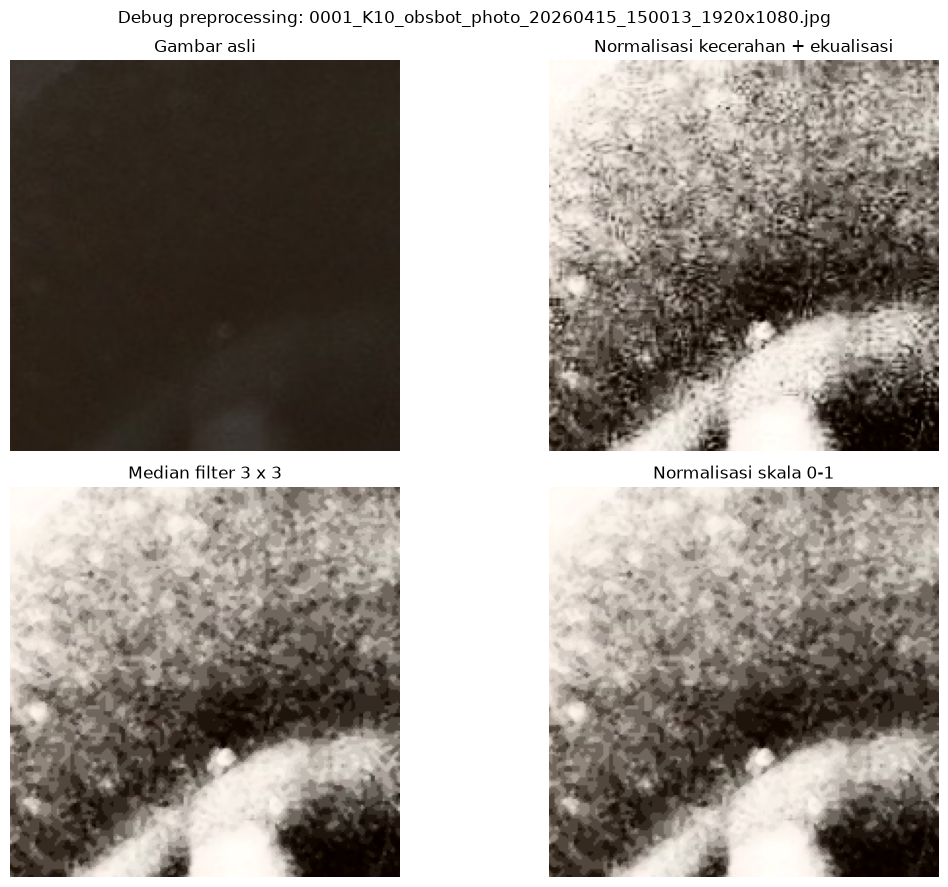

Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0001_K10_obsbot_photo_20260415_150013_1920x1080.png
\nDebug: 0002_K10_obsbot_photo_20260416_110013_1920x1080.jpg
  Gambar asli: shape=(200, 200, 3), rentang=[6.0000, 83.0000]
  Normalisasi kecerahan + ekualisasi: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Median filter 3 x 3: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Normalisasi skala 0-1: shape=(200, 200, 3), rentang=[0.0000, 1.0000]


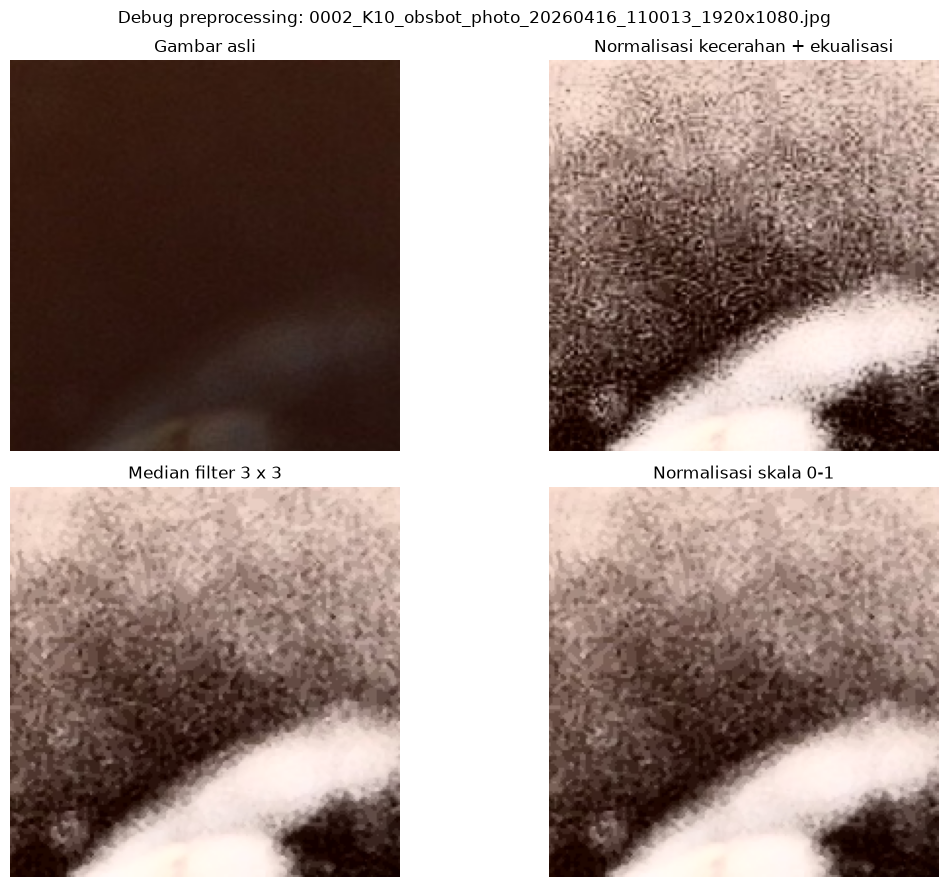

Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0002_K10_obsbot_photo_20260416_110013_1920x1080.png
\nDebug: 0003_K10_obsbot_photo_20260417_115513_1920x1080.jpg
  Gambar asli: shape=(200, 200, 3), rentang=[3.0000, 91.0000]
  Normalisasi kecerahan + ekualisasi: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Median filter 3 x 3: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Normalisasi skala 0-1: shape=(200, 200, 3), rentang=[0.0000, 1.0000]


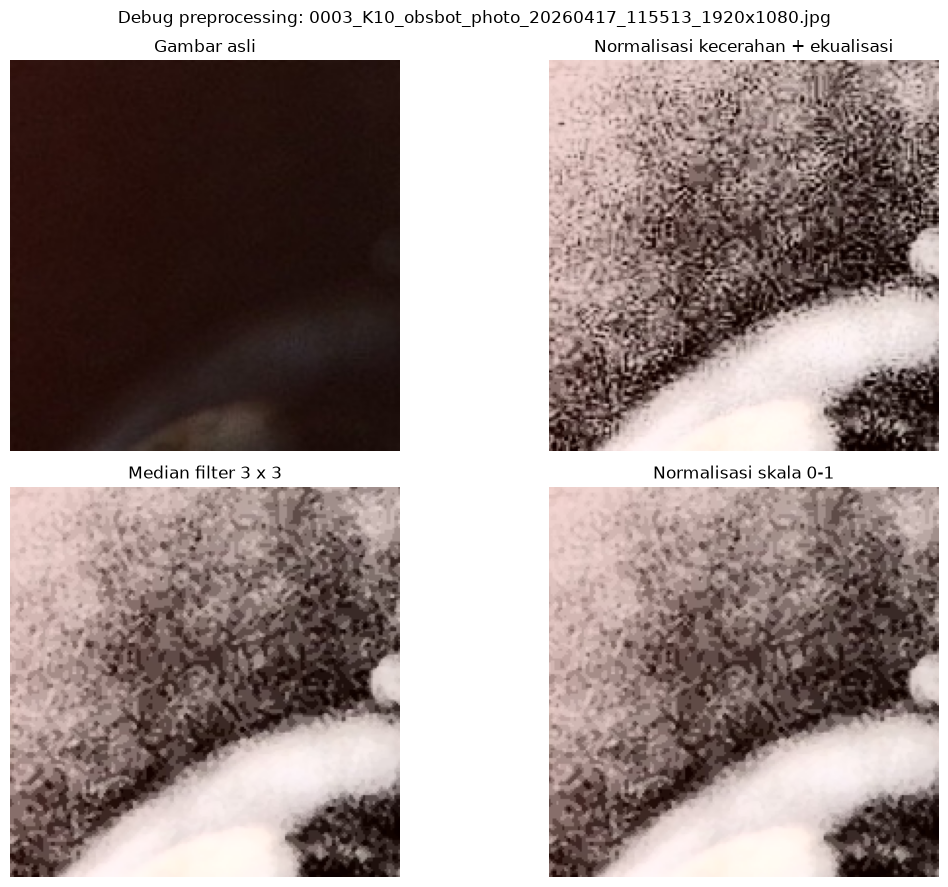

Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0003_K10_obsbot_photo_20260417_115513_1920x1080.png
\nDebug: 0004_K10_obsbot_photo_20260418_115513_1920x1080.jpg
  Gambar asli: shape=(200, 200, 3), rentang=[5.0000, 99.0000]
  Normalisasi kecerahan + ekualisasi: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Median filter 3 x 3: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Normalisasi skala 0-1: shape=(200, 200, 3), rentang=[0.0000, 1.0000]


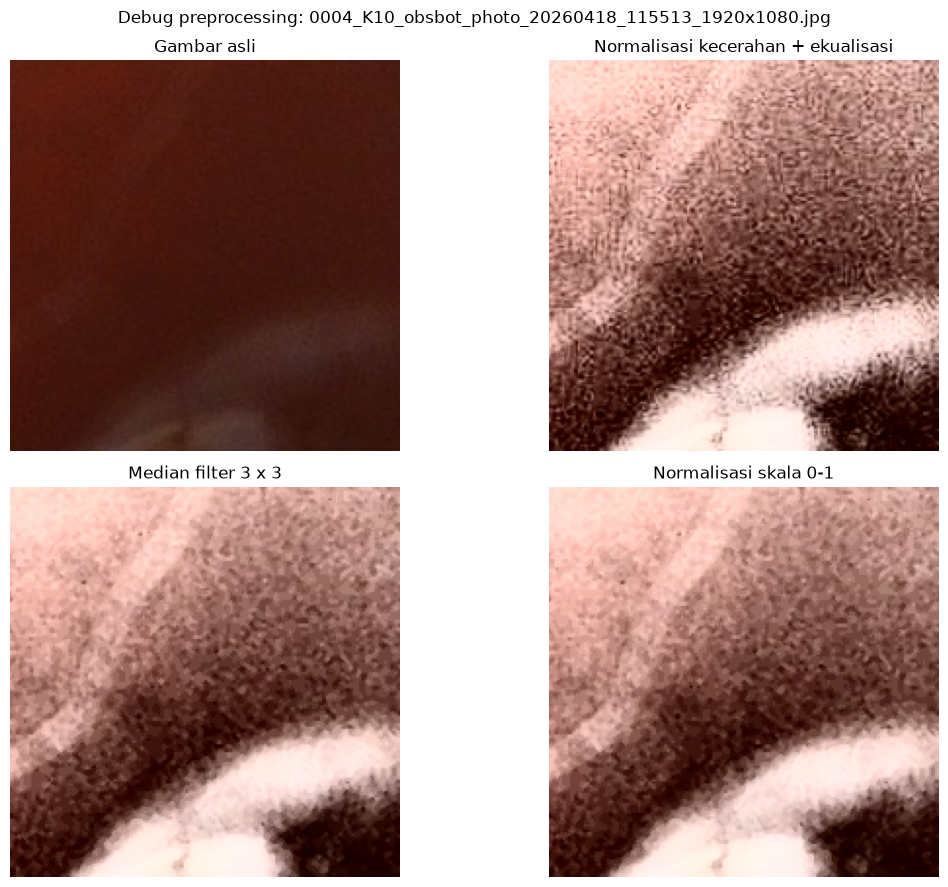

Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0004_K10_obsbot_photo_20260418_115513_1920x1080.png
\nDebug: 0005_K10_obsbot_photo_20260419_101513_1920x1080.jpg
  Gambar asli: shape=(200, 200, 3), rentang=[6.0000, 114.0000]
  Normalisasi kecerahan + ekualisasi: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Median filter 3 x 3: shape=(200, 200, 3), rentang=[0.0000, 255.0000]
  Normalisasi skala 0-1: shape=(200, 200, 3), rentang=[0.0000, 1.0000]


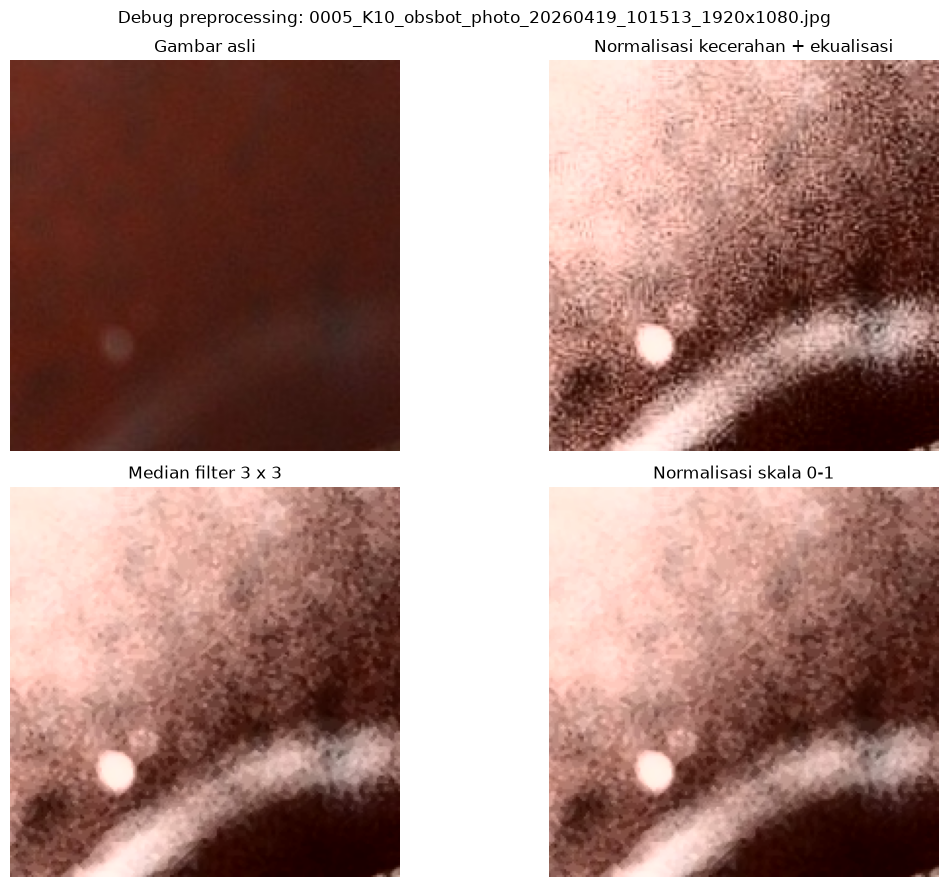

Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0005_K10_obsbot_photo_20260419_101513_1920x1080.png
Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0006_K10_obsbot_photo_20260420_113013_1920x1080.png
Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0007_K10_obsbot_photo_20260420_214513_1920x1080.png
Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0008_K10_obsbot_photo_20260422_102013_1920x1080.png
Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images\0009_K10_obsbot_photo_20260423_110611_1920x1080.png
Tersimpan: D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Ma

In [4]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Sesuaikan INPUT_DIR bila gambar Anda berada di folder dataset yang berbeda.
INPUT_DIR =Path(r"D:\00 Kuliah\TA\Experiment\Dataset\Data Gambar\Gambar Final")
OUTPUT_DIR = Path(r"D:\00 Kuliah\TA\Experiment\Model\Real-Time Algal Monitoring Using Novel Machine Learning Approaches\preprocessed_images")

MEDIAN_KERNEL_SIZE = 3
DEBUG_VISUALIZE = True  # Tampilkan perbandingan tahap untuk sejumlah gambar.
DEBUG_IMAGE_LIMIT = 5

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def normalize_brightness_and_equalize(image_bgr: np.ndarray) -> np.ndarray:
    """Normalize luminance range, then equalize its histogram, preserving color."""
    ycrcb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2YCrCb)
    luminance, cr, cb = cv2.split(ycrcb)

    # Stretch luminance to the full 8-bit range before histogram equalization.
    normalized_luminance = cv2.normalize(
        luminance, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX
    ).astype(np.uint8)
    equalized_luminance = cv2.equalizeHist(normalized_luminance)

    adjusted = cv2.merge((equalized_luminance, cr, cb))
    return cv2.cvtColor(adjusted, cv2.COLOR_YCrCb2BGR)


def preprocess_image(image_bgr: np.ndarray) -> tuple[np.ndarray, dict[str, np.ndarray]]:
    """Apply pipeline and return final RGB float image plus intermediate stages."""
    stages = {"Gambar asli": cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)}
    original_height, original_width = image_bgr.shape[:2]

    corrected = normalize_brightness_and_equalize(image_bgr)
    stages["Normalisasi kecerahan + ekualisasi"] = cv2.cvtColor(
        corrected, cv2.COLOR_BGR2RGB
    )
    denoised = cv2.medianBlur(corrected, MEDIAN_KERNEL_SIZE)
    stages["Median filter 3 x 3"] = cv2.cvtColor(denoised, cv2.COLOR_BGR2RGB)

    # OpenCV loads BGR; convert to RGB for typical machine-learning pipelines.
    rgb = cv2.cvtColor(denoised, cv2.COLOR_BGR2RGB)
    normalized = rgb.astype(np.float32) / 255.0
    stages["Normalisasi skala 0-1"] = normalized

    if normalized.shape[:2] != (original_height, original_width):
        raise RuntimeError("Dimensi gambar berubah selama preprocessing.")

    return normalized, stages


def show_debug_stages(image_path: Path, stages: dict[str, np.ndarray]) -> None:
    """Display each pipeline stage and print its shape and value range."""
    print(f"\\nDebug: {image_path.name}")
    figure, axes = plt.subplots(2, 2, figsize=(12, 9))
    for axis, (stage_name, image) in zip(axes.flat, stages.items()):
        axis.imshow(image)
        axis.set_title(stage_name)
        axis.axis("off")
        print(
            f"  {stage_name}: shape={image.shape}, "
            f"rentang=[{image.min():.4f}, {image.max():.4f}]"
        )
    figure.suptitle(f"Debug preprocessing: {image_path.name}")
    figure.tight_layout()
    plt.show()
    plt.close(figure)


def main() -> None:
    input_dir = INPUT_DIR.resolve()
    output_dir = OUTPUT_DIR.resolve()
    if not input_dir.is_dir():
        raise FileNotFoundError(f"Folder input tidak ditemukan: {input_dir}")

    image_paths = sorted(
        path for path in input_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    if not image_paths:
        print(f"Tidak ada gambar ditemukan di: {input_dir}")
        return

    debug_count = 0
    for image_path in image_paths:
        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image_bgr is None:
            print(f"Lewati gambar yang tidak dapat dibaca: {image_path}")
            continue

        processed, stages = preprocess_image(image_bgr)
        if DEBUG_VISUALIZE and debug_count < DEBUG_IMAGE_LIMIT:
            show_debug_stages(image_path, stages)
            debug_count += 1

        # Normalisasi 0-1 dipakai di RAM; PNG menyimpan piksel 8-bit.
        output_rgb = np.rint(processed * 255.0).clip(0, 255).astype(np.uint8)
        output_bgr = cv2.cvtColor(output_rgb, cv2.COLOR_RGB2BGR)
        relative_path = image_path.relative_to(input_dir).with_suffix(".png")
        output_path = output_dir / relative_path
        output_path.parent.mkdir(parents=True, exist_ok=True)
        if not cv2.imwrite(str(output_path), output_bgr):
            print(f"Gagal menyimpan: {output_path}")
            continue
        print(f"Tersimpan: {output_path}")


if __name__ == "__main__":
    main()
